In [9]:
#import Libraries and tools;
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

#Read data file;
PROJECT_ROOT = Path.cwd() if Path.cwd().name == 'user_behavior_analysis' else Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / 'src'))

#Modular import of Python script functions;
from data_cleaning import clean_user_behavior
from data_analysis import (
    behavior_type_distribution,
    user_item_sequential_funnel,
    cart_without_purchase_users,
    daily_active_users,
    daily_purchase_trend,
    high_value_users,
    hourly_activity,
    repurchase_analysis,
    summarize_behavior_metrics,
    top_categories_by_purchase,
    user_segmentation,
    purchase_segment_summary,

    category_conversion_analysis,

    comparison_between_weekday_and_weekend,
    hour_activity_comparison_within_week,
    distribution_of_behavior_within_week,
    user_tag_period,
    high_value_comparison_within_day,
    top_activity_category,
    activity_purchasing_segment_user,
    category_converison_decision_cycle,
    repurchase_cycle,
    purchase_category_combos
)

#Configure visual chart styles and adapt Chinese fonts
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams['axes.unicode_minus'] = False

#Configuration file path;
raw_path = PROJECT_ROOT / 'data' / 'raw_user_behavior.csv'
cleaned_path = PROJECT_ROOT / 'data' / 'cleaned_user_behavior.csv'
df = clean_user_behavior(raw_path, cleaned_path)
df.head()

FIGURES_DIR = PROJECT_ROOT / 'figures'



Cleaning summary
- Row row:100,000
- Clean rows:99,956
- Removed rows:44
- Output file:C:\Users\Administrator\Desktop\user_behaivor_analysis\data\cleaned_user_behavior.csv


In [2]:
FIGURES_DIR = PROJECT_ROOT / 'figures'
print(FIGURES_DIR)

C:\Users\Administrator\Desktop\user_behaivor_analysis\figures


In [3]:
def save_fig(name : str,dpi = 180,show : bool = True):
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / f'{name}.png',
        dpi=dpi,
        bbox_inches='tight',
        facecolor='w')
    if show:
        plt.show()
    plt.close()
    print(f"{name}图表保存成功，路径{FIGURES_DIR / f'{name}.png'}。")


In [3]:
#1.summarize_behavior_metrics*2.
metrics = summarize_behavior_metrics(df)
pd.Series(metrics)

total_behavior                  99956.0000
uv                                983.0000
item_count                      64440.0000
category_count                   3128.0000
pv_count                        89665.0000
fav_count                        2744.0000
cart_count                       5446.0000
buy_count                        2101.0000
browse_to_purchase_user_rate        0.6827
cart_to_purchase_user_rate          0.7289
dtype: float64

,behavior_type,behavior_count,behavior_share
0,pv,89665,0.8970
1,cart,5446,0.0545
2,fav,2744,0.0275
3,buy,2101,0.0210


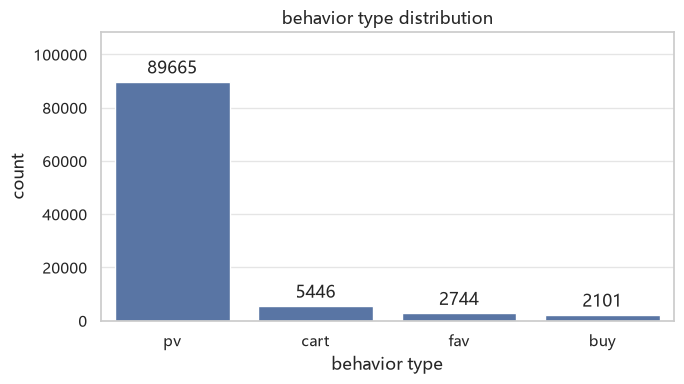

behavior_type_distribution图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\behavior_type_distribution.png。


In [23]:
#behavior_type_distribution*5.
behavior_dist = behavior_type_distribution(df)
display(behavior_dist)


fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=behavior_dist, x='behavior_type',y='behavior_count')
ax.bar_label(ax.containers[0], fmt='%d', padding=3)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
plt.title('behavior type distribution')
plt.xlabel('behavior type')
plt.ylabel('count')
save_fig('behavior_type_distribution')

,date,dau
0,2017-11-25,695
1,2017-11-26,723
2,2017-11-27,708
3,2017-11-28,720
4,2017-11-29,724
5,2017-11-30,712
6,2017-12-01,718
7,2017-12-02,962
8,2017-12-03,965


,date,purchase_count,purchase_users
0,2017-11-25,179,123
1,2017-11-26,215,138
2,2017-11-27,250,150
3,2017-11-28,221,141
4,2017-11-29,221,150
5,2017-11-30,259,158
6,2017-12-01,214,145
7,2017-12-02,270,173
8,2017-12-03,272,181


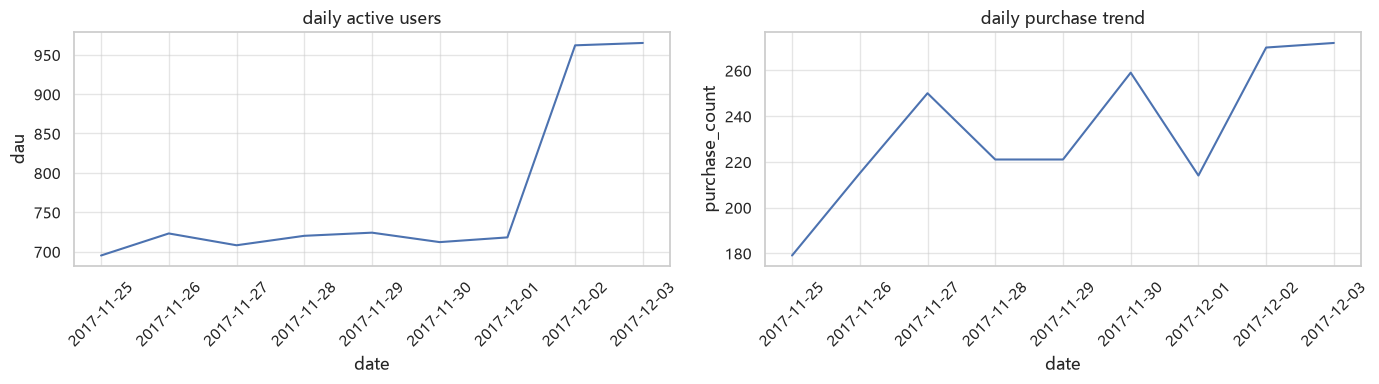

daily_active_users_trend图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\daily_active_users_trend.png。


In [16]:
#daily_active_users*6. daily_purchase_trend*7.
dau = daily_active_users(df)
purchase_tred = daily_purchase_trend(df)
display(dau)
display(purchase_tred)

fig,axes = plt.subplots(1,2,figsize=(14,4))
sns.lineplot(data=dau,x='date',y='dau',markers='o',ax=axes[0])
axes[0].set_title('daily active users')
axes[0].tick_params(axis='x',rotation=45)

sns.lineplot(data=purchase_tred,x='date',y='purchase_count',markers='o',ax=axes[1])
axes[1].set_title('daily purchase trend')
axes[1].tick_params(axis='x',rotation=45)
save_fig('daily_active_users_trend')




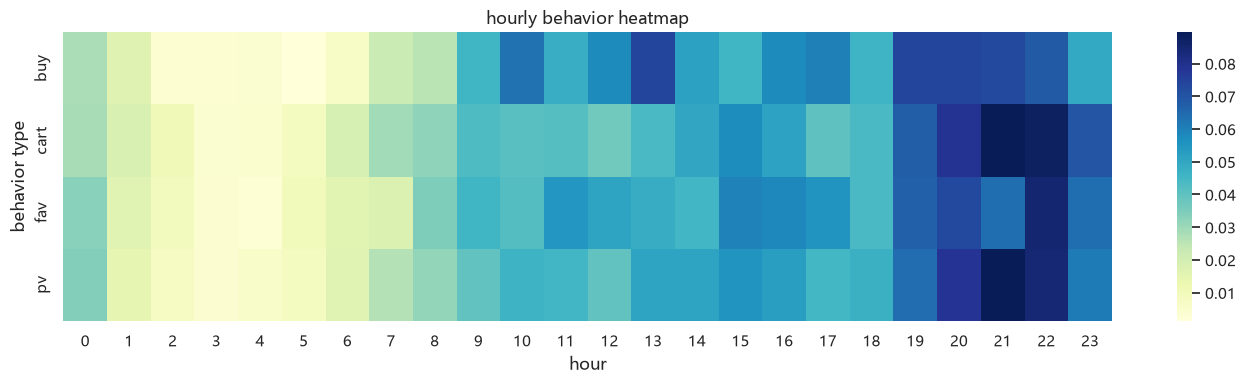

hourly_pivot_heatmap图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\hourly_pivot_heatmap.png。


In [17]:
#hourly_activity*8.
hourly = hourly_activity(df)
hourly_pivot = hourly.pivot_table(
    index='behavior_type',
    columns='hour',
    values='behavior_count',
    fill_value=0)

pivot_normalized = hourly_pivot.div(hourly_pivot.sum(axis=1), axis=0)

plt.figure(figsize=(14,4))
sns.heatmap(pivot_normalized,cmap='YlGnBu', annot=False)
plt.title('hourly behavior heatmap')
plt.xlabel('hour')
plt.ylabel('behavior type')
save_fig('hourly_pivot_heatmap')
plt.show()

In [7]:
# 9. 11. 12. 13.
display(top_categories_by_purchase(df,top_n=10))
display(pd.Series(repurchase_analysis(df)))
display(cart_without_purchase_users(df).head(10))
display(high_value_users(df),top_n=10)

,category_id,purchase_count,buyer_count
0,2735466,38,32
1,1464116,35,29
2,4145813,29,25
3,4801426,28,23
4,2885642,25,21
5,3002561,25,19
6,4756105,23,19
7,3607361,21,17
8,1299190,20,18
9,4789432,19,17


total_buyers        671.0000
repurchase_users    442.0000
repurchase_rate       0.6587
dtype: float64

,user_id,cart_count
0,1000,2
1,100038,6
2,100083,11
3,100178,20
4,100199,8
5,100240,8
6,100283,4
7,100322,2
8,100336,1
9,100386,4


,user_id,purchase_count,distinct_items_bought,distinct_categories_bought,active_days,value_score
0,1003983,43,40,34,9,338
1,1003901,31,30,20,8,243
2,100101,28,28,26,9,231
3,1000488,19,18,14,9,154
4,1000723,16,15,11,7,128
5,1001305,15,15,11,9,125
6,1002031,16,12,9,9,122
7,1001866,15,13,11,6,118
8,100134,14,14,11,8,117
9,100116,13,12,12,9,110


In [8]:
#Calculate the users for pv, cart, and buy based on the funnel conversion rate of pv*4.
funnel = pd.DataFrame({
    'step':['pv_users','cart_users','buy_users'],
    'users':[
        df.loc[df['behavior_type'] =='pv','user_id'].nunique(),
        df.loc[df['behavior_type'] =='cart','user_id'].nunique(),
        df.loc[df['behavior_type'] =='buy','user_id'].nunique()
    ]
})
funnel['conversion_from_pv'] = (funnel['users'] / funnel.loc[0,'users']).round(4)
display(funnel)

,step,users,conversion_from_pv
0,pv_users,980,1.0000
1,cart_users,723,0.7378
2,buy_users,671,0.6847


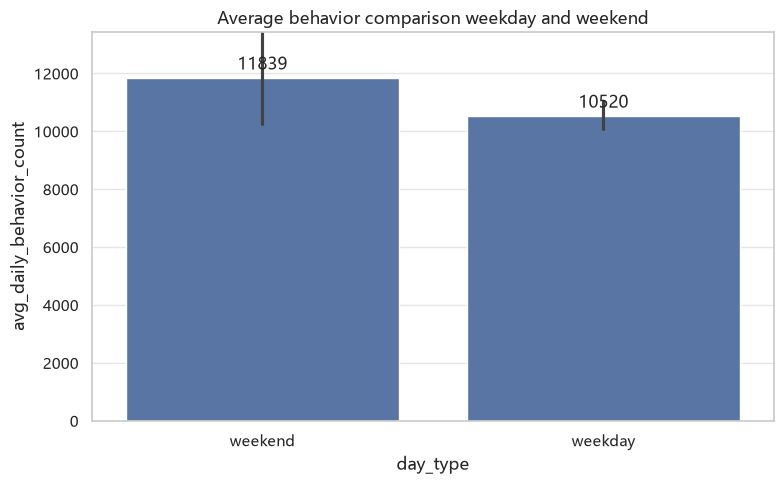

Average behavior comparison weekday and weekend图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\Average behavior comparison weekday and weekend.png。


In [12]:
#Comparison of user behavior on weekdays and weekends *-1.
result = comparison_between_weekday_and_weekend(df)

fig,ax = plt.subplots(figsize=(8,5))
sns.barplot(data=result.reset_index(),x='day_type', y='avg_behavior',ax=ax)
ax.bar_label(ax.containers[0],fmt='%.0f',padding=3)
ax.set_ylim(0,ax.get_ylim()[1] * 0.95)
plt.title('Average behavior comparison weekday and weekend')
plt.ylabel('avg_daily_behavior_count')
save_fig('Average behavior comparison weekday and weekend')

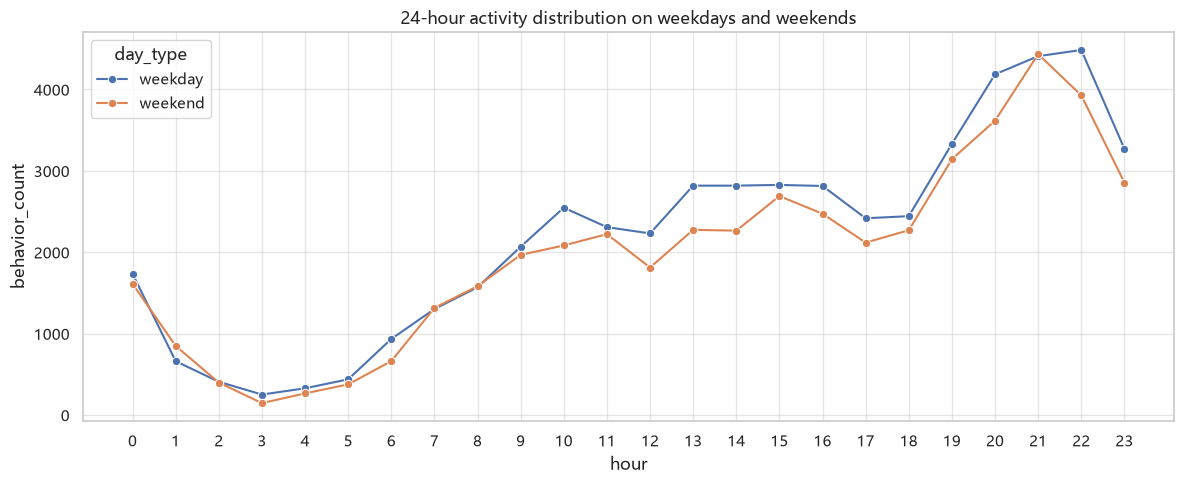

24-hour activity distribution within week图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\24-hour activity distribution within week.png。


In [19]:
#Weekdays vs Weekends: 24-Hour Activity Distribution*-2.
result = hour_activity_comparison_within_week(df)
plt.figure(figsize=(12, 5))
sns.lineplot(data=result, x='hour', y='count', hue='day_type', marker='o')
plt.title('24-hour activity distribution on weekdays and weekends')
plt.xlabel('hour')
plt.ylabel('behavior_count')
plt.xticks(range(0, 24))
save_fig('24-hour activity distribution within week')

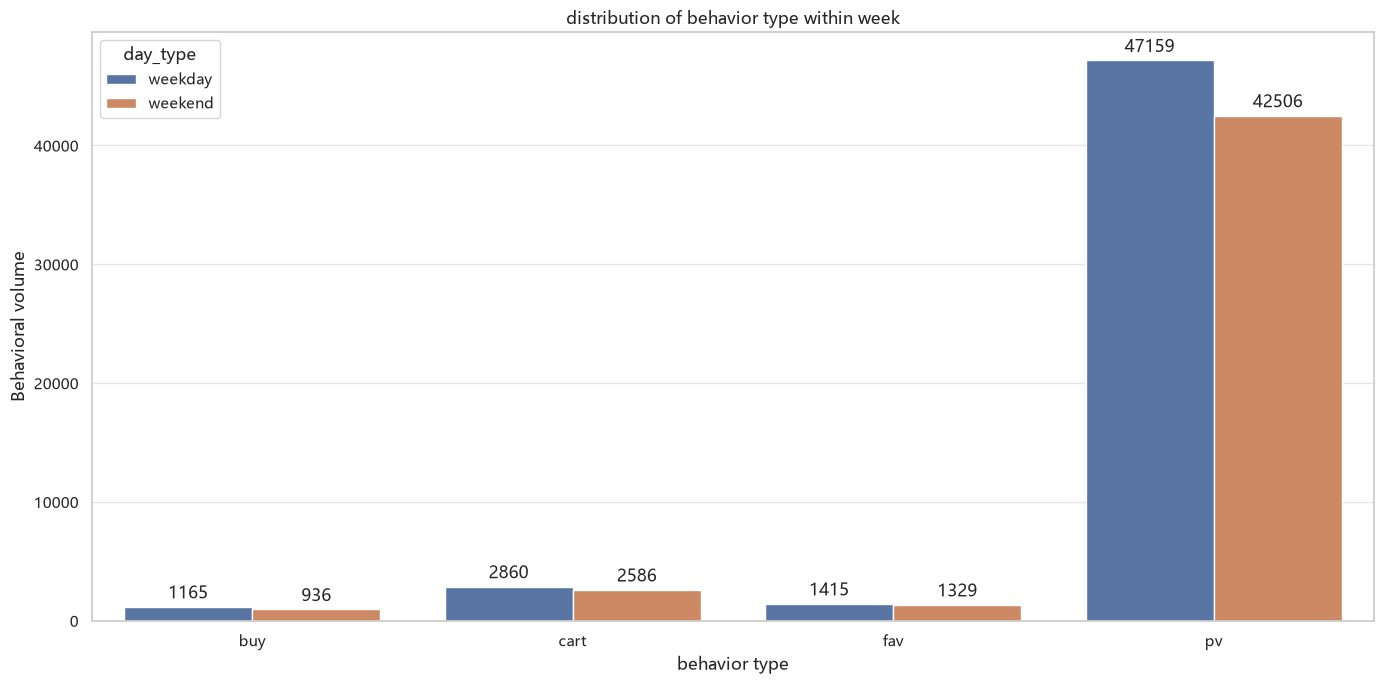

distribution of behavior type within week图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\distribution of behavior type within week.png。


In [20]:
#distribution_of_behavior_within_week*-3.
result = distribution_of_behavior_within_week(df)

fig,ax = plt.subplots(figsize=(14,7))
sns.barplot(data=result, x='behavior_type', y='count', hue='day_type',ax=ax)
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f',padding=3)

plt.title('distribution of behavior type within week')
plt.xlabel('behavior type')
plt.ylabel('Behavioral volume')
save_fig('distribution of behavior type within week')

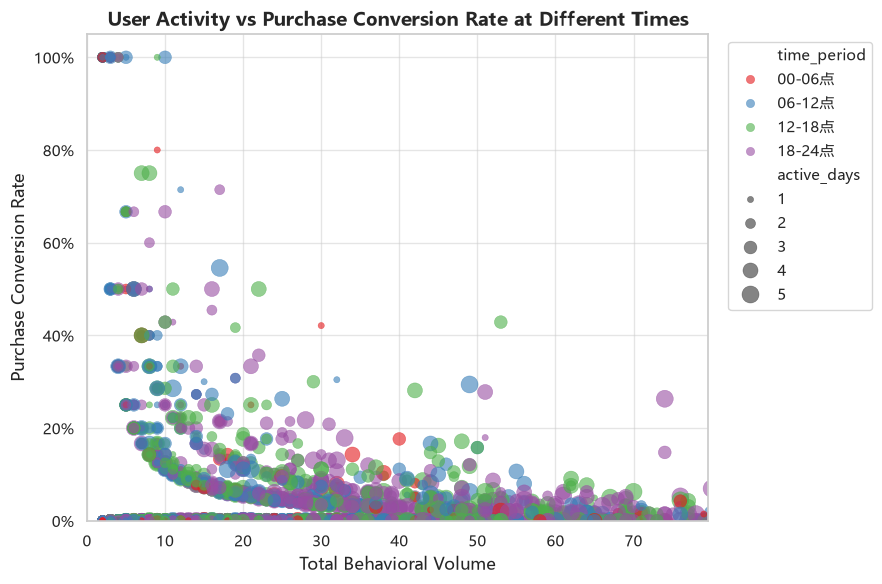

User Activity vs Purchase Conversion Rate at Different Times图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\User Activity vs Purchase Conversion Rate at Different Times.png。


In [23]:
# user_tag_period*-4.
result = user_tag_period(df)

result_clean = result[(result['buy_rate'] <= 1.0) & (result['total_behavior'] >= 2)].copy()
x_max = result_clean['total_behavior'].quantile(0.97)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=result_clean,
    x='total_behavior',
    y='buy_rate',
    hue='time_period',
    size='active_days',
    sizes=(20, 150),        # 稍微调小了气泡的最大尺寸，防糊
    alpha=0.6,              # 透明度调低一点，点叠在一起也能看清
    palette='Set1',
    edgecolor=None          # 去掉边框，看起来更柔和
)

plt.xlim(0, x_max)
plt.ylim(0, 1.05)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))

plt.title(f'User Activity vs Purchase Conversion Rate at Different Times', fontsize=14, fontweight='bold')
plt.xlabel('Total Behavioral Volume', fontsize=12)
plt.ylabel('Purchase Conversion Rate', fontsize=12)

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

save_fig('User Activity vs Purchase Conversion Rate at Different Times')


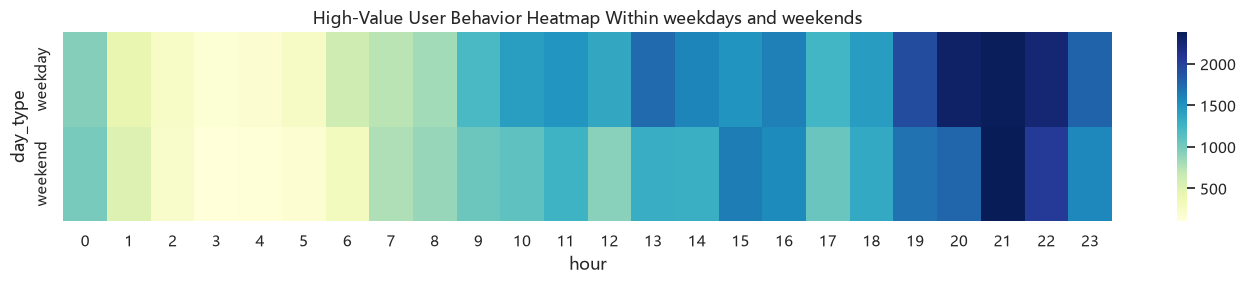

High-Value User Behavior Within a week图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\High-Value User Behavior Within a week.png。


In [4]:
#high_value_comparison_within_day*-5.
result = high_value_comparison_within_day(df)

pivot = result.pivot(index='day_type', columns='hour', values='count').fillna(0)
plt.figure(figsize=(14, 3))
sns.heatmap(pivot, cmap='YlGnBu', annot=False)
plt.title('High-Value User Behavior Heatmap Within weekdays and weekends')
plt.xlabel('hour')
plt.ylabel('day_type')
save_fig('High-Value User Behavior Within a week')

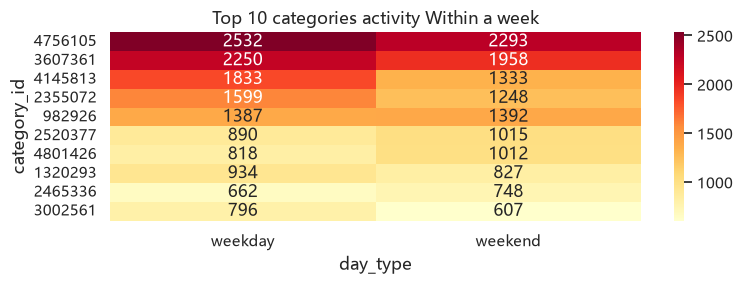

Top 10 categories activity Within a week图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\Top 10 categories activity Within a week.png。


In [32]:
#top_activity_category*-5.
plt.figure(figsize=(8, 3))
result_top = top_activity_category(df,top_n=10, ascending=False)
top_pivot = result_top.pivot(index='category_id', columns='day_type', values='count').fillna(0)
#从result调用函数中提取category_id情况，并tolist
top_order = result_top['category_id'].drop_duplicates().tolist()
#将pivot按照tolist的category_id顺序强制排序
top_pivot = top_pivot.reindex(top_order)

sns.heatmap(top_pivot, cmap='YlOrRd', annot=True, fmt='.0f')

plt.title('Top 10 categories activity Within a week')
plt.xlabel('day_type')
plt.ylabel('category_id')
save_fig('Top 10 categories activity Within a week')




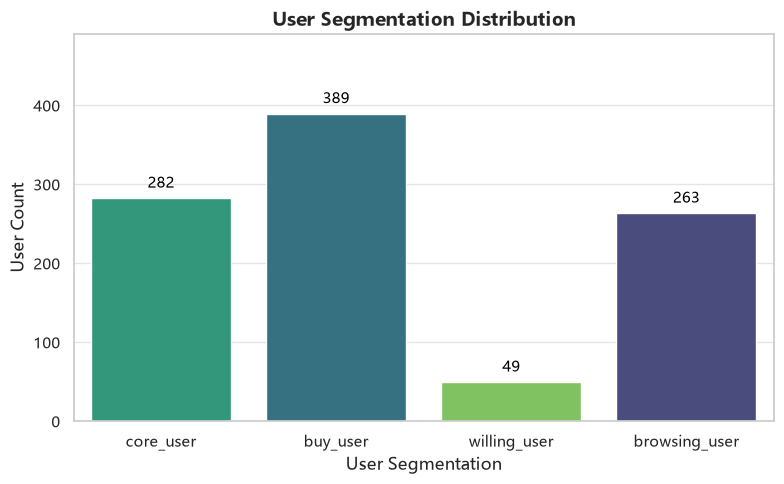

User Segmentation Distribution图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\User Segmentation Distribution.png。


In [29]:
#activity_purchasing_segment_user*-6.
result = activity_purchasing_segment_user(df)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=result,
    x='segment_user',
    y='user_count',
    order=['core_user', 'buy_user', 'willing_user', 'browsing_user'],
    hue='segment_user',
    legend=False,
    palette='viridis',
    ax=ax
)
ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%d',
        padding=5,
        fontsize=11,
        color='black'
    )
plt.title('User Segmentation Distribution', fontsize=14, fontweight='bold')
plt.xlabel('User Segmentation', fontsize=12)
plt.ylabel('User Count', fontsize=12)

save_fig('User Segmentation Distribution')

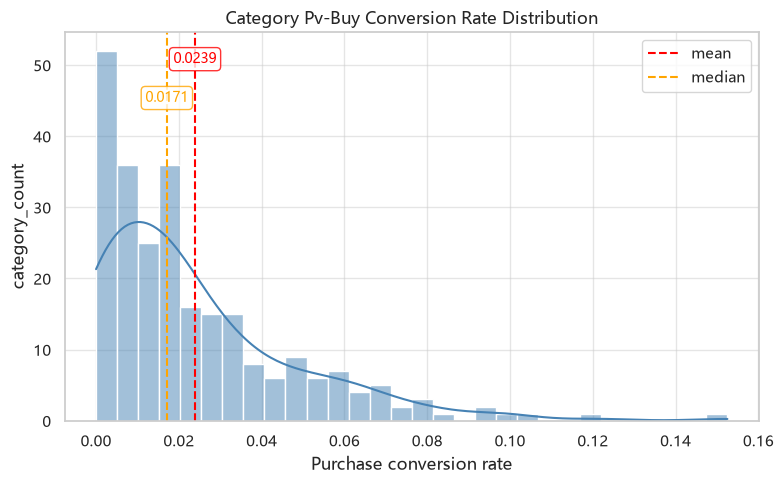

category_conversion_rate_dist图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\category_conversion_rate_dist.png。


In [5]:
#category_converison_decision_cycle*-7.
result = category_converison_decision_cycle(df,10,ascending=False)

#图一--品类转化情况
fig,ax1 = plt.subplots(figsize=(8,5))
sns.histplot(
    data=result['all_category_rates'],
    bins=30,
    kde=True,
    color='steelblue',
    ax=ax1
)
ax1.set_title('Category Pv-Buy Conversion Rate Distribution')
ax1.set_xlabel('Purchase conversion rate')
ax1.set_ylabel('category_count')

mean_0 = result['all_category_rates'].mean()
median_0 = result['all_category_rates'].median()
ax1.axvline(mean_0, color='red', linestyle='--', label=f'mean')
ax1.axvline(median_0, color='orange', linestyle='--', label=f'median')

ymax_0 = ax1.get_ylim()[1]
ax1.text(mean_0, ymax_0 * 0.95, f'{mean_0:.4f}',
             color='red', ha='center', va='top', fontsize=10,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='red', alpha=0.8))
ax1.text(median_0, ymax_0 * 0.85, f'{median_0:.4f}',
             color='orange', ha='center', va='top', fontsize=10,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='orange', alpha=0.8))
ax1.legend()
save_fig('category_conversion_rate_dist')





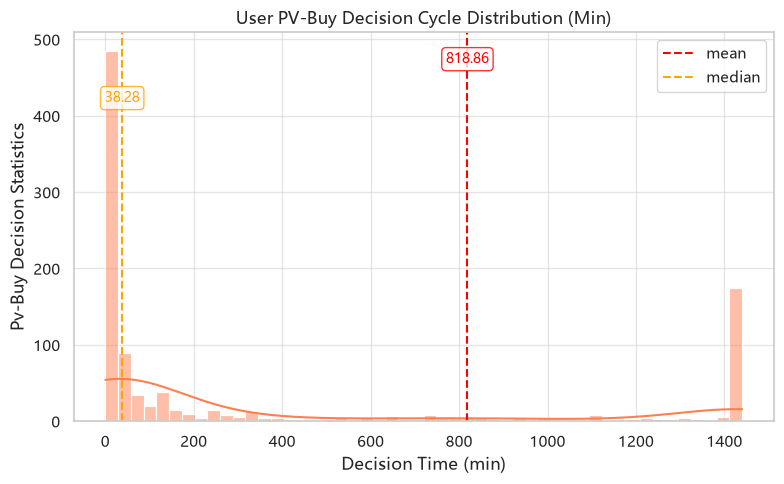

User PV-Buy Decision Cycle Distribution图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\User PV-Buy Decision Cycle Distribution.png。


In [6]:
#category_converison_decision_cycle*-7.
result = category_converison_decision_cycle(df,10,ascending=False)

fig2,ax2 = plt.subplots(figsize=(8, 5))
#直方图+核密度估计曲线，sns.histplot(data数据,bins分箱,kde叠加密度曲线)
sns.histplot(
    data=result['all_decision_minutes'].clip(upper=1440), #clip(upper，lower)取数据内小于upper的，大于lower的
    bins=50,
    kde=True,
    color='coral',
    ax=ax2
)
ax2.set_title('User PV-Buy Decision Cycle Distribution (Min)')
ax2.set_xlabel('Decision Time (min)')
ax2.set_ylabel('Pv-Buy Decision Statistics')

mean_1 = result['all_decision_minutes'].mean()
median_1 = result['all_decision_minutes'].median()
ax2.axvline(mean_1, color='red', linestyle='--', label=f'mean')
ax2.axvline(median_1, color='orange', linestyle='--', label=f'median')

ymax_1 = ax2.get_ylim()[1]
ax2.text(mean_1, ymax_1 * 0.95, f'{mean_1:.2f}',
             color='red', ha='center', va='top', fontsize=10,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='red', alpha=0.8))
ax2.text(median_1, ymax_1 * 0.85, f'{median_1:.2f}',
             color='orange', ha='center', va='top', fontsize=10,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='orange', alpha=0.8))

ax2.legend()
save_fig('User PV-Buy Decision Cycle Distribution')


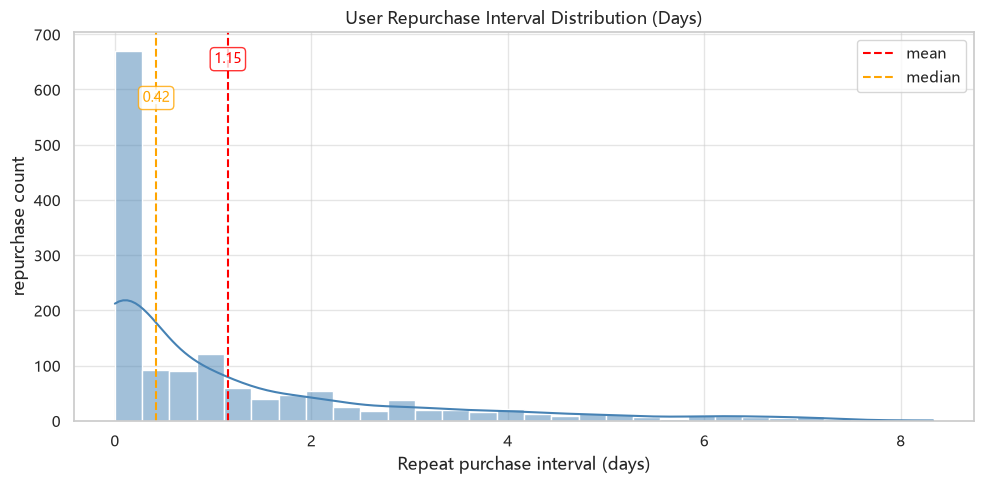

User Repurchase Interval Distribution (Days)图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\User Repurchase Interval Distribution (Days).png。


In [26]:
#repurchase_cycle*-9.
result = repurchase_cycle(df)
repurchase = result['repurchase_list']

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    repurchase['days_between'].clip(upper=30),   # 截断到 30 天，避免长尾
    bins=30,
    kde=True,
    color='steelblue',
    ax=ax
)

mean_val = result['avg_repurchase_interval']
median_val = result['median_repurchase_interval']
plt.axvline(mean_val, color='red', linestyle='--', label=f'mean')
plt.axvline(median_val, color='orange', linestyle='--', label=f'median')

ymax = ax.get_ylim()[1]
ax.text(mean_val, ymax * 0.95, f'{mean_val:.2f}',
        color='red', ha='center', va='top', fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='red', alpha=0.8))

ax.text(median_val, ymax * 0.85, f'{median_val:.2f}',
        color='orange', ha='center', va='top', fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='orange', alpha=0.8))

plt.title('User Repurchase Interval Distribution (Days)')
plt.xlabel('Repeat purchase interval (days)')
plt.ylabel('repurchase count')
plt.legend()
save_fig('User Repurchase Interval Distribution (Days)')

In [14]:
#Top 10 most commonly bought product category combinations by users *-10
result = purchase_category_combos(df)
print(result)

      category_a  category_b  co_count
596      2735466     4801426         5
618      1464116     2735466         4
1802     2735466     3002561         3
680       722945     1516409         3
1337     1575622     4801426         3
753      1464116     4217906         3
619      1464116     4801426         3
333      2735466     4145813         3
379      3299155     4145813         3
686       903809     1169503         3


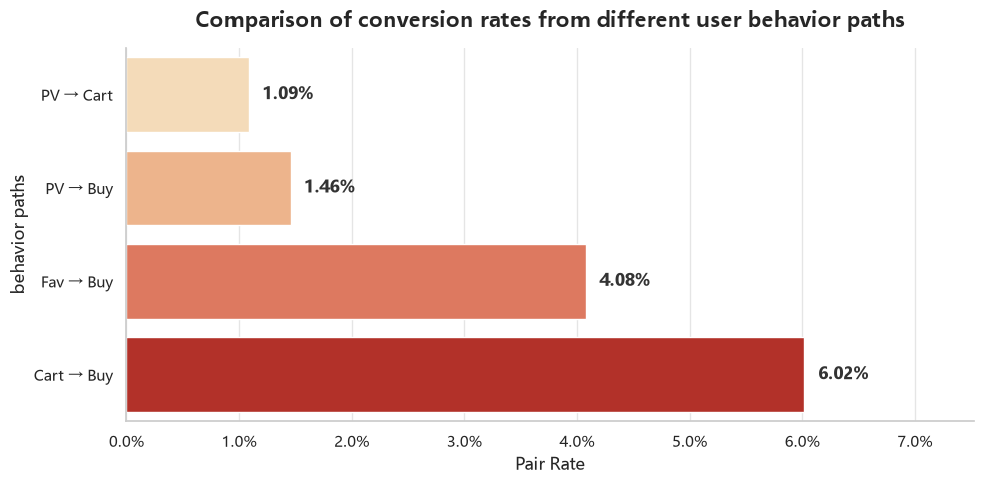

user items sequential funnel图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\user items sequential funnel.png。


In [7]:
#user_item_sequential_funnel(3.
funnel_result = user_item_sequential_funnel(df)
rate_data = pd.DataFrame({
    'path': [
        'PV → Cart',
        'PV → Buy',
        'Fav → Buy',
        'Cart → Buy'
    ],
    'rate': [
        funnel_result['pv_to_cart_pair_rate'],
        funnel_result['pv_to_buy_pair_rate'],
        funnel_result['fav_to_buy_pair_rate'],
        funnel_result['cart_to_buy_pair_rate']
    ]
})
rate_data = rate_data.sort_values('rate', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=rate_data,
    x='rate',
    y='path',
    hue='path',
    legend=False,
    palette='OrRd',
    ax=ax
)
#百分比数值标签
for i, row in rate_data.iterrows():
    ax.text(
        row['rate'] + (rate_data['rate'].max() * 0.02),
        i,
        f"{row['rate'] * 100:.2f}%",
        va='center',
        fontsize=12,
        fontweight='bold',
        color='#333333'
    )
plt.title('Comparison of conversion rates from different user behavior paths', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Pair Rate', fontsize=12)
plt.ylabel('behavior paths', fontsize=12)

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:.1f}%".format(x * 100)))
ax.set_xlim(0, rate_data['rate'].max() * 1.25)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
save_fig('user items sequential funnel')


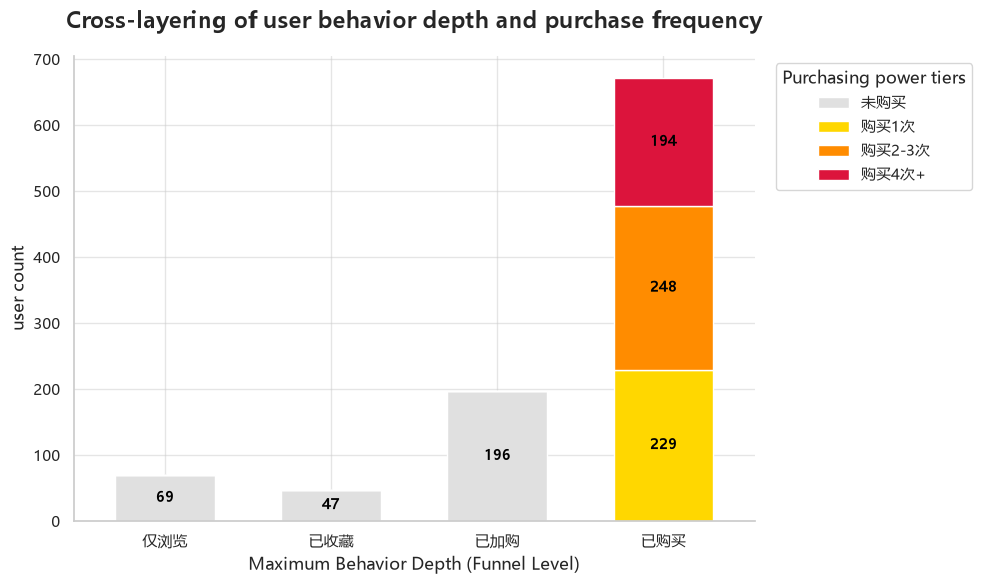

user segmentation图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\user segmentation.png。


In [8]:
#user_segmentation(13.
seg_result = user_segmentation(df)
behavior_map = {
    'browse_only': '仅浏览',
    'favorited': '已收藏',
    'added_to_cart': '已加购',
    'purchased': '已购买'
}
purchase_map = {
    'no_purchase': '未购买',
    'one_pruchase': '购买1次',       # 注意：你的代码里原来拼写成了 pruchase，这里兼容一下
    'one_purchase': '购买1次',
    'two_to_three': '购买2-3次',
    'four_plus': '购买4次+'
}

# 清洗映射并生成中文列
seg_result['行为深度'] = seg_result['behavior_depth'].map(behavior_map)
seg_result['购买分层'] = seg_result['purchase_segment'].map(purchase_map)

# 2. 透视数据：为了画堆叠图，需要把“购买分层”变成列
pivot_df = seg_result.pivot(index='行为深度', columns='购买分层', values='users').fillna(0)

# 调整一下行和列的顺序，让图表符合业务逻辑：从浅到深，从少到多
row_order = ['仅浏览', '已收藏', '已加购', '已购买']
col_order = ['未购买', '购买1次', '购买2-3次', '购买4次+']
pivot_df = pivot_df.reindex(index=row_order, columns=col_order).fillna(0)

# 3. 开始画图
fig, ax = plt.subplots(figsize=(10, 6))

# 自定义颜色（从浅灰到深红，体现价值梯度）
colors = ['#E0E0E0', '#FFD700', '#FF8C00', '#DC143C']

# 画堆叠柱状图
pivot_df.plot(kind='bar', stacked=True, color=colors, ax=ax, edgecolor='white', width=0.6)

# 4. 在柱子上添加数据标签（人数）
for c in ax.containers:
    # 过滤掉数值为 0 的标签，避免重叠
    labels = [int(v) if v > 0 else '' for v in c.datavalues]
    ax.bar_label(c, labels=labels, label_type='center', fontsize=10, color='black', fontweight='bold')

# 5. 图表美化
plt.title('Cross-layering of user behavior depth and purchase frequency', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Maximum Behavior Depth (Funnel Level)', fontsize=12)
plt.ylabel('user count', fontsize=12)
plt.xticks(rotation=0) # 保持X轴标签水平

# 调整图例位置到图表外侧
plt.legend(title='Purchasing power tiers', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=11, title_fontsize=12)

# 去掉顶部和右侧边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
save_fig('user segmentation')


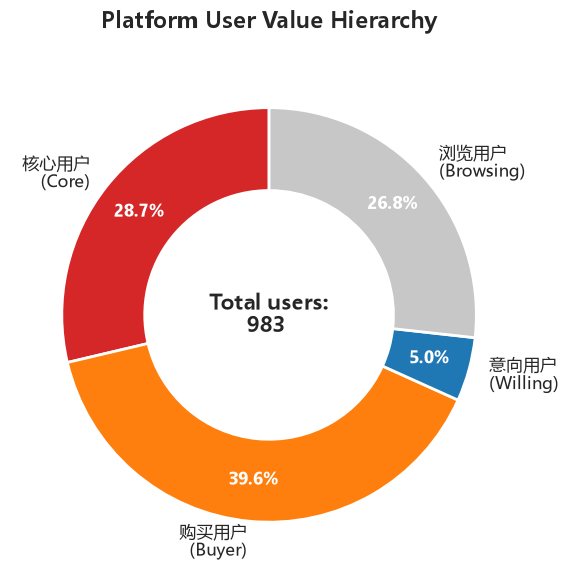

activity_purchasing_segment_user图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\activity_purchasing_segment_user.png。


In [14]:
#activity_purchasing_segment_user(7.
seg_data = activity_purchasing_segment_user(df)
label_map = {
    'core_user': '核心用户\n(Core)',
    'buy_user': '购买用户\n(Buyer)',
    'willing_user': '意向用户\n(Willing)',
    'browsing_user': '浏览用户\n(Browsing)'
}
seg_data['label_cn'] = seg_data['segment_user'].map(label_map)

# 按照价值顺序强制排序
order = ['核心用户\n(Core)', '购买用户\n(Buyer)', '意向用户\n(Willing)', '浏览用户\n(Browsing)']
seg_data['label_cn'] = pd.Categorical(seg_data['label_cn'], categories=order, ordered=True)
seg_data = seg_data.sort_values('label_cn')

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#d62728', '#ff7f0e', '#1f77b4', '#c7c7c7']

# 画环形图
wedges, texts, autotexts = ax.pie(
    seg_data['user_count'],
    labels=seg_data['label_cn'],
    autopct='%1.1f%%',       # 显示百分比
    pctdistance=0.80,        # 百分比标签离圆心的距离
    startangle=90,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2) # 环的宽度和白色分割线
)

# 设置百分比字体
plt.setp(autotexts, size=12, weight="bold", color="white")
plt.setp(texts, size=12)

# 在中心加上总人数
total_users = seg_data['user_count'].sum()
ax.text(0, 0, f'Total users:\n{total_users:,} ', ha='center', va='center', fontsize=15, fontweight='bold')

plt.title('Platform User Value Hierarchy', fontsize=16, fontweight='bold', pad=20)
save_fig('activity_purchasing_segment_user')


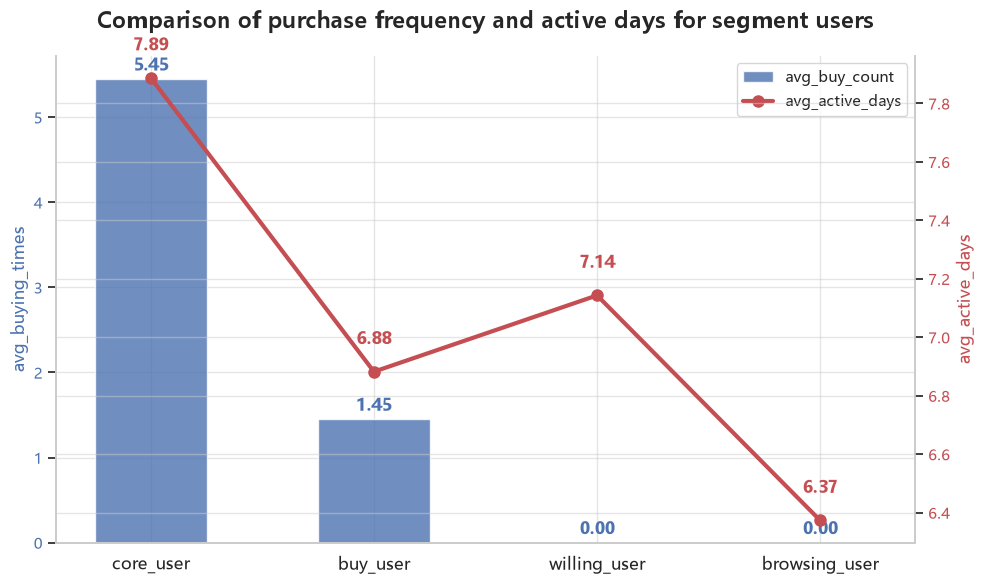

Comparison of purchase frequency and active days for segment users图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\Comparison of purchase frequency and active days for segment users.png。


In [15]:
#activity_purchasing_segment_user(7.
seg_data = activity_purchasing_segment_user(df)

fig, ax1 = plt.subplots(figsize=(10, 6))
x = np.arange(len(seg_data))
bar_width = 0.5
bars = ax1.bar(x, seg_data['avg_buy_count'], width=bar_width, color='#4C72B0', alpha=0.8, label='avg_buy_count')
ax1.set_ylabel('avg_buying_times', fontsize=12, color='#4C72B0')
ax1.tick_params(axis='y', labelcolor='#4C72B0')
ax1.set_xticks(x)
ax1.set_xticklabels(seg_data['segment_user'], fontsize=12)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.2f}', ha='center', va='bottom', color='#4C72B0', fontweight='bold')

ax2 = ax1.twinx()
line = ax2.plot(x, seg_data['avg_active_days'], color='#C44E52', marker='o', linewidth=3, markersize=8, label='avg_active_days')
ax2.set_ylabel('avg_active_days', fontsize=12, color='#C44E52')
ax2.tick_params(axis='y', labelcolor='#C44E52')

for i, val in enumerate(seg_data['avg_active_days']):
    ax2.text(i, val + 0.08, f'{val:.2f}', ha='center', va='bottom', color='#C44E52', fontweight='bold')

plt.title('Comparison of purchase frequency and active days for segment users', fontsize=16, fontweight='bold', pad=20)
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', fontsize=11)

save_fig('Comparison of purchase frequency and active days for segment users')


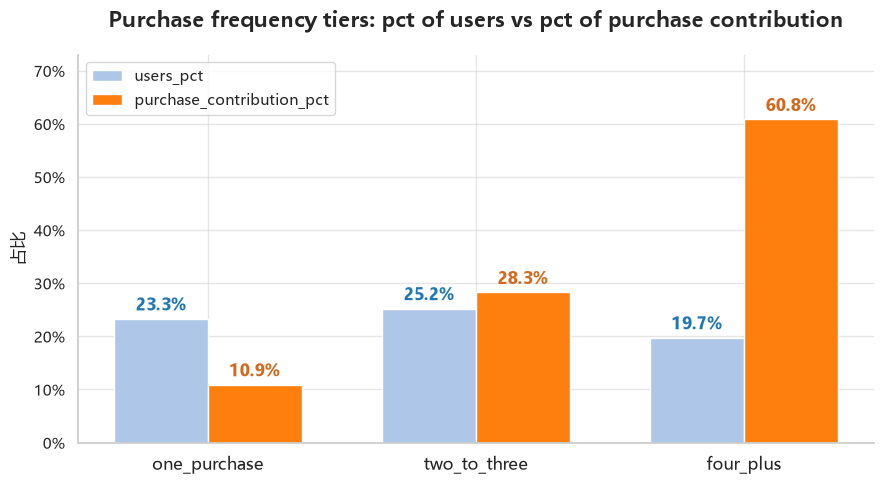

purchase_segment_summary图表保存成功，路径C:\Users\Administrator\Desktop\user_behaivor_analysis\figures\purchase_segment_summary.png。


In [7]:
#purchase_segment_summary(15.
summary = purchase_segment_summary(df)
plot_data = summary[summary['purchase_segment'] != 'no_purchase'].copy()

x = np.arange(len(plot_data))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 5))

rects1 = ax1.bar(x - width/2, plot_data['user_ratio'], width, label='users_pct', color='#AEC7E8')
rects2 = ax1.bar(x + width/2, plot_data['buy_ratio'], width, label='purchase_contribution_pct', color='#FF7F0E')

ax1.bar_label(rects1, labels=[f'{v:.1%}' for v in plot_data['user_ratio']], padding=3, color='#1F77B4', fontweight='bold')
ax1.bar_label(rects2, labels=[f'{v:.1%}' for v in plot_data['buy_ratio']], padding=3, color='#D2691E', fontweight='bold')

ax1.set_ylabel('占比', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(plot_data['purchase_segment'], fontsize=12)
ax1.set_ylim(0, max(plot_data['buy_ratio'].max(), plot_data['user_ratio'].max()) * 1.2)
ax1.legend(fontsize=11)

ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))

plt.title('Purchase frequency tiers: pct of users vs pct of purchase contribution', fontsize=15, fontweight='bold', pad=20)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

save_fig('purchase_segment_summary')


In [14]:
#category_conversion_analysis
category_conversion_analysis(df)

,category_id,buy_count,cart_count,fav_count,pv_count,browse_to_buy_rate,cart_to_buy_rate
0,2735466,38,74,26,1114,0.0341,0.5135
1,1464116,35,50,21,628,0.0557,0.7
2,4145813,29,151,110,2876,0.0101,0.1921
3,4801426,28,104,55,1643,0.017,0.2692
4,2885642,25,42,16,750,0.0333,0.5952
5,3002561,25,69,34,1275,0.0196,0.3623
6,4756105,23,197,96,4509,0.0051,0.1168
7,3607361,21,134,104,3949,0.0053,0.1567
8,1299190,20,41,17,574,0.0348,0.4878
9,4789432,19,26,7,379,0.0501,0.7308
